# 03 · Model comparison
Each family tuned by 5-fold CV on train (PR-AUC); compared on validation; thresholds from out-of-fold training predictions.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)
from ml import config
report = lambda name: json.loads((config.REPORTS_DIR / name).read_text())

In [2]:
mc = report('model_comparison.json')
rows = []
for r in mc['models']:
    v = r['validation']
    rows.append({'model': r['display_name'], 'cv_pr_auc': r['tuning']['cv_pr_auc_mean'], 'val_pr_auc': v['pr_auc'], 'val_roc_auc': v['roc_auc'], 'val_precision': v['precision'], 'val_recall': v['recall'], 'val_f1': v['f1'], 'threshold': r['oof_threshold']})
pd.DataFrame(rows).set_index('model')

,cv_pr_auc,val_pr_auc,val_roc_auc,val_precision,val_recall,val_f1,threshold
model,,,,,,,
Logistic Regression,0.4667,0.5436,0.9355,0.2807,0.7164,0.4034,0.0872
Random Forest,0.9109,0.8989,0.9731,0.9344,0.8507,0.8906,0.3931
Histogram Gradient Boosting,0.8970,0.8719,0.9655,0.8710,0.8060,0.8372,0.3536
XGBoost,0.8790,0.8767,0.9713,0.8088,0.8209,0.8148,0.2540


In [3]:
print('Selected:', mc['selected'], '| rule:', mc['selection_metric'])
{r['display_name']: r['tuning']['best_params'] for r in mc['models']}

Selected: random_forest | rule: validation PR-AUC (average precision)


{'Logistic Regression': {'clf__C': 1.0, 'clf__class_weight': None}, 'Random Forest': {'n_estimators': 500, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': 16, 'class_weight': None}, 'Histogram Gradient Boosting': {'min_samples_leaf': 10, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 1.0, 'class_weight': None}, 'XGBoost': {'subsample': 0.8, 'scale_pos_weight': 1.0, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.8}}

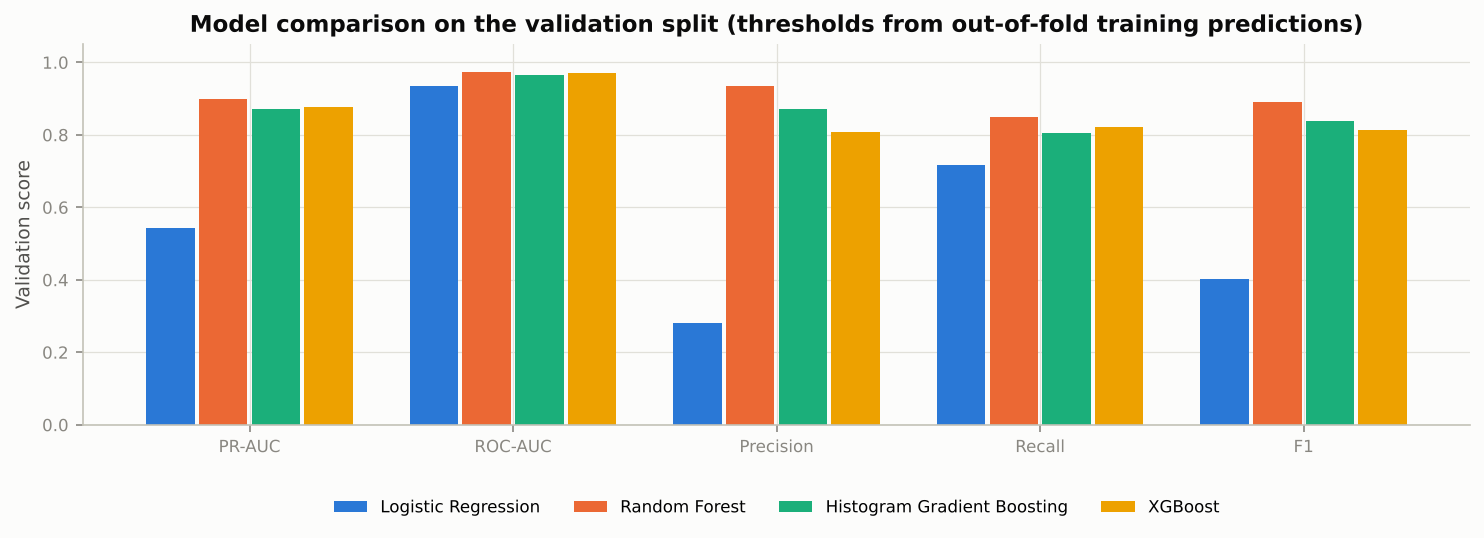

In [4]:
from IPython.display import Image
Image(str(config.FIGURES_DIR / '07_model_comparison.png'))

## Threshold choice (validation)

In [5]:
m = report('metrics.json')
m['thresholds']['policy']

{'medium_threshold': 0.047, 'high_threshold': 0.3931, 'method': 'HIGH = F2-optimal threshold on out-of-fold training predictions; MEDIUM = highest threshold keeping out-of-fold training recall >= 95%'}

In [6]:
pd.DataFrame([{k: v for k, v in r.items() if k != 'confusion_matrix'} for r in m['thresholds']['validation_tradeoff']]).set_index('threshold')[['precision','recall','f1','f2']]

,precision,recall,f1,f2
threshold,,,,
0.05,0.4026,0.9254,0.5611,0.7346
0.10,0.5175,0.8806,0.6519,0.7723
0.20,0.8143,0.8507,0.8321,0.8432
0.30,0.8906,0.8507,0.8702,0.8584
0.40,0.9344,0.8507,0.8906,0.8663
0.50,0.9655,0.8358,0.8960,0.8589
0.60,0.9818,0.8060,0.8852,0.8359
0.70,1.0000,0.7612,0.8644,0.7994
0.80,1.0000,0.7164,0.8348,0.7595


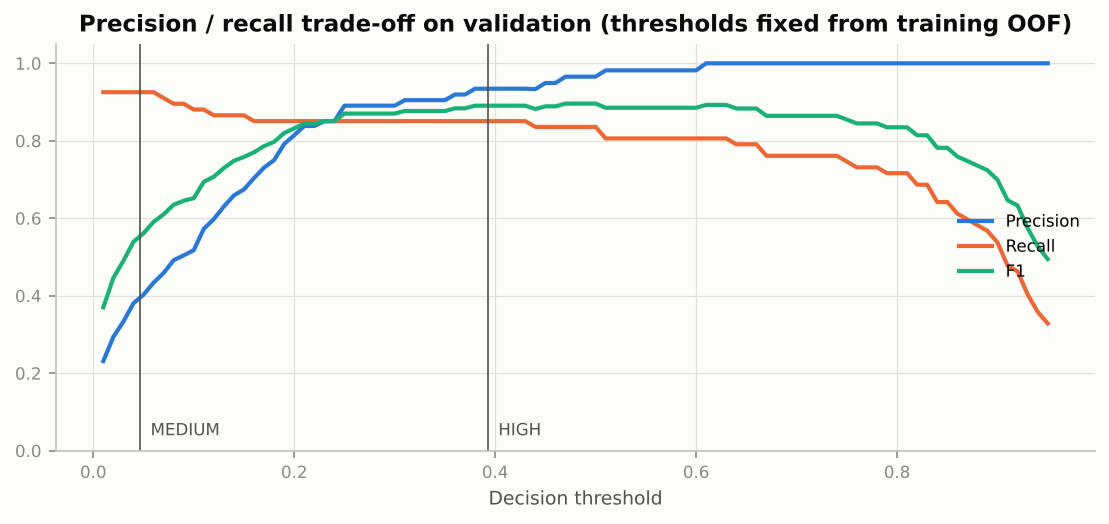

In [7]:
Image(str(config.FIGURES_DIR / '12_validation_threshold_tradeoff.png'))